# Electrodynamics from Scratch — Lecture 5: The Delta Function and the Inverse Problem

A point charge is a singular source: all of its charge sits at a single point, so its density $\rho$ is zero everywhere except at that point, where it is infinite. The **Dirac delta function** $\delta^3(\mathbf{r})$ is the bookkeeping device for exactly this situation. It is zero everywhere except at the origin, yet its integral over any volume containing the origin is one. With it, Gauss's law in differential form, $\nabla \cdot \mathbf{E} = \rho/\varepsilon_0$, says something very compact about a point charge:

$$\nabla \cdot \left(\frac{\hat{\mathbf{r}}}{r^2}\right) = 4\pi\,\delta^3(\mathbf{r}), \qquad\text{or equivalently}\qquad \nabla^2 \left(\frac{1}{r}\right) = -4\pi\,\delta^3(\mathbf{r}).$$

The potential of a point source, $V(\mathbf{r}) = \dfrac{q}{4\pi\varepsilon_0}\,\dfrac{1}{r}$, is the Green's function of Poisson's equation $-\varepsilon_0 \nabla^2 V = \rho$: convolve it with any charge distribution and you get that distribution's potential.

No computer can represent a true delta function, so we work with **regularized deltas**: narrow Gaussians

$$\delta_\sigma(x) = \frac{1}{\sigma\sqrt{2\pi}}\,e^{-x^2/2\sigma^2},$$

whose integral is exactly $1$ for every width $\sigma$. As $\sigma \to 0$ the peak grows without bound while the area stays fixed — the defining property of the delta. On a grid, the narrowest useful delta is a few grid spacings wide; anything narrower is under-resolved.

This lecture also covers the **inverse problem**: given the potential $V$ measured on a grid, recover the source from Poisson's equation, $\rho = -\varepsilon_0 \nabla^2 V$. Doing this reliably rests on the vector-calculus identities behind the Feynman trick — $\nabla \times (\nabla f) = 0$ and $\nabla \cdot (\nabla \times \mathbf{A}) = 0$ — which are what make it legitimate to write $\mathbf{E} = -\nabla V$ and $\mathbf{B} = \nabla \times \mathbf{A}$ in the first place. We verify both identities numerically, then solve an inverse problem: take the potential of a known point charge on a 3D grid, apply $-\varepsilon_0 \nabla^2$, and watch the point source reappear as a discrete delta.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import electrodynamics_from_scratch as eds

## Gaussian approximations to the delta function

Each curve below has unit area — `eds.gaussian_delta` builds a properly normalized Gaussian — but as $\sigma$ shrinks the same area is squeezed into an ever taller, ever narrower spike. That is precisely the delta function's defining behavior.

sigma = 0.400   peak =     1.00   integral = 0.98757610
sigma = 0.200   peak =     1.99   integral = 0.99999942
sigma = 0.100   peak =     3.99   integral = 1.00000000
sigma = 0.050   peak =     7.98   integral = 1.00000000


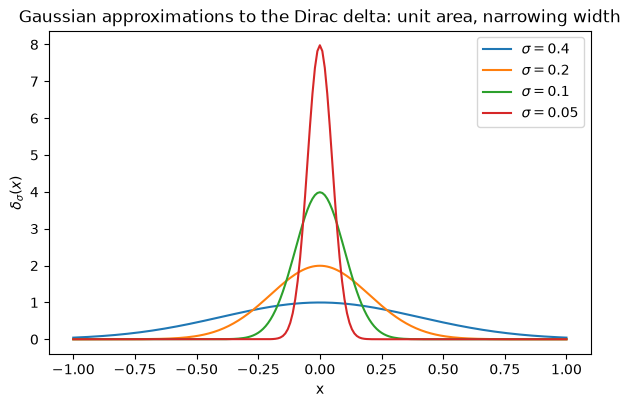

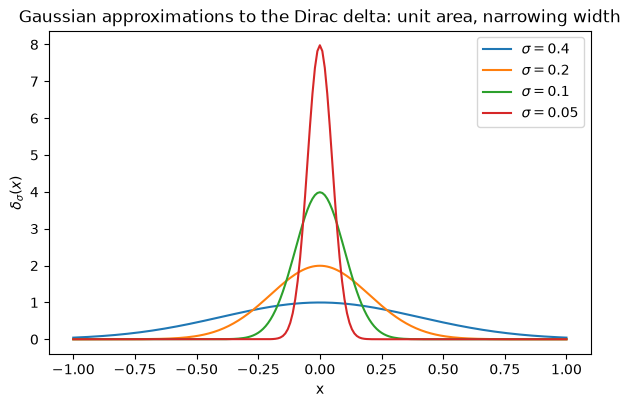

In [2]:
x = np.linspace(-1.0, 1.0, 201)

fig, ax = plt.subplots(figsize=(7, 4.2))
for sigma in [0.4, 0.2, 0.1, 0.05]:
    g = eds.gaussian_delta(x, 0.0, sigma)
    area = np.trapz(g, x)
    print(f"sigma = {sigma:5.3f}   peak = {g.max():8.2f}   integral = {area:.8f}")
    ax.plot(x, g, label=rf"$\sigma={sigma}$")
ax.set_xlabel("x")
ax.set_ylabel(r"$\delta_\sigma(x)$")
ax.set_title("Gaussian approximations to the Dirac delta: unit area, narrowing width")
ax.legend()
fig

## A regularized point source on a 2D grid

A 2D point source is the product of two 1D deltas. On a grid with spacing $\Delta x$, we build it from Gaussians a few cells wide, so its grid sum times $\Delta x^2$ still integrates to $1$. This blob is exactly what a finite-difference Poisson solver "sees" when you hand it a point charge.

grid spacing dx = 0.0200, sigma = 0.0600
total charge  sum(rho) * dx^2 = 1.00000000   (should be 1)


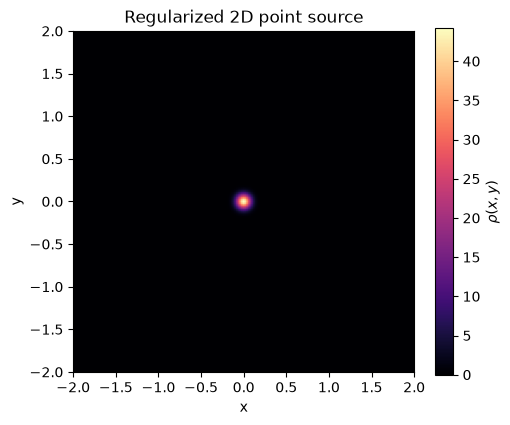

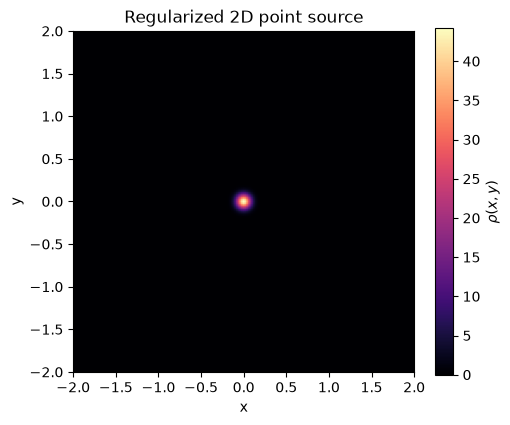

In [3]:
n = 201
xs = np.linspace(-2.0, 2.0, n)
dx = xs[1] - xs[0]
sigma = 3 * dx

# grid convention for this package: 2D arrays are indexed [y, x]
rho = (eds.gaussian_delta(xs, 0.0, sigma)[None, :]
       * eds.gaussian_delta(xs, 0.0, sigma)[:, None])

print(f"grid spacing dx = {dx:.4f}, sigma = {sigma:.4f}")
print(f"total charge  sum(rho) * dx^2 = {rho.sum() * dx**2 :.8f}   (should be 1)")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(rho, extent=[-2, 2, -2, 2], origin="lower", cmap="magma")
fig.colorbar(im, ax=ax, label=r"$\rho(x,y)$")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Regularized 2D point source")
fig

## The potential of a point source

The function $V(\mathbf{r}) = q/(4\pi\varepsilon_0 r)$ satisfies $-\varepsilon_0 \nabla^2 V = q\,\delta^3(\mathbf{r})$: everywhere except at the source it is harmonic ($\nabla^2 V = 0$), and all of the mismatch is concentrated at the one point. On a 2D slice through the charge, the equipotentials are concentric circles and the field lines are radial. Note that we place the charge slightly off the grid sampling used for the plot — the potential diverges exactly at the charge, and the package refuses to evaluate it there.

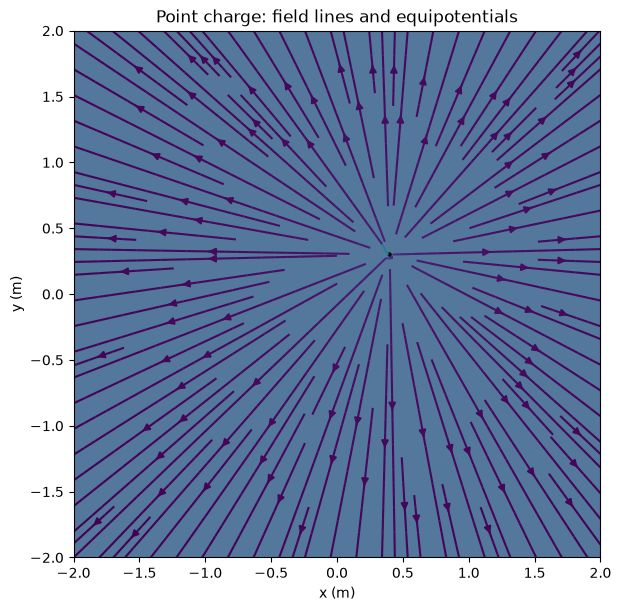

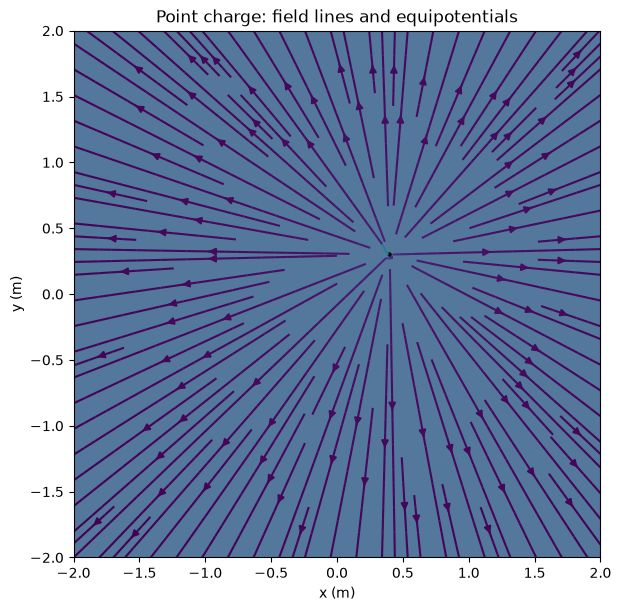

In [4]:
q = 2.0
pos = np.array([0.4, 0.3, 0.0])

def as_points(X, Y):
    return np.stack([X.ravel(), Y.ravel(), np.zeros(X.size)], axis=1)

potential_func = lambda X, Y: eds.point_charge_potential(q, pos, as_points(X, Y)).reshape(X.shape)
field_func = lambda X, Y: (lambda E: (E[..., 0], E[..., 1]))(
    eds.point_charge_field(q, pos, as_points(X, Y)).reshape(X.shape + (3,)))

fig, ax = eds.plot_field_and_potential(
    field_func, potential_func, extent=2.0,
    title="Point charge: field lines and equipotentials",
)
fig

## The $1/r$ decay of the point-source potential

Along a ray away from the charge, the potential falls off exactly as $1/r$ — the signature of a delta-function source. On a log–log plot a power law is a straight line, and the slope of this one is $-1$.

fitted power-law exponent: -1.0000   (expected -1)


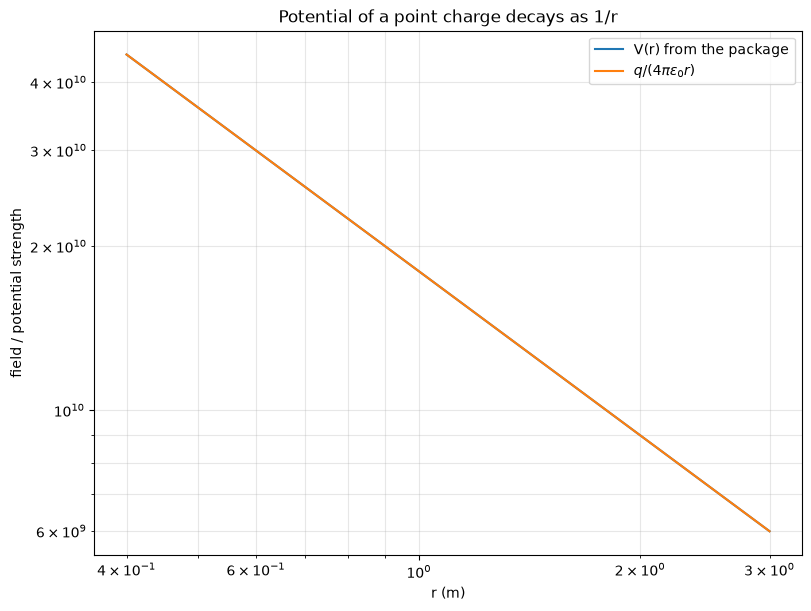

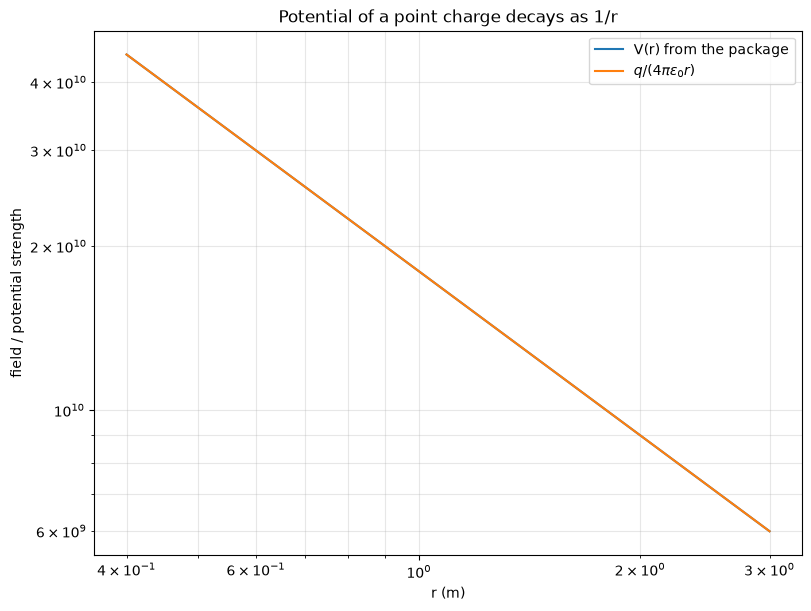

In [5]:
r_values = np.linspace(0.4, 3.0, 50)
pts = np.stack([r_values, np.zeros_like(r_values), np.zeros_like(r_values)], axis=1)

V = eds.point_charge_potential(q, np.zeros(3), pts)
V_analytic = q / (4 * np.pi * eds.EPSILON_0 * r_values)

slope = eds.power_law_fit(r_values, V)[1]
print(f"fitted power-law exponent: {slope:.4f}   (expected -1)")

fig, ax = eds.plot_decay(
    r_values,
    {"V(r) from the package": V, r"$q/(4\pi\varepsilon_0 r)$": V_analytic},
    loglog=True,
    title="Potential of a point charge decays as 1/r",
)
fig

## Identity 1 (the Feynman trick): $\nabla \times (\nabla f) = 0$

Because the curl of any gradient vanishes, an electrostatic field can be written as $\mathbf{E} = -\nabla V$. To check this numerically we hand `eds.fields_from_potentials` a scalar potential $f$ and a zero vector potential, so it returns $\mathbf{E} = -\nabla f$; then we take the discrete curl of that field. It vanishes to machine precision.

max |curl(-grad f)| = 8.715e-15
max |E + grad f|    = 0.000e+00
max |B| (curl of A = 0) = 0.000e+00


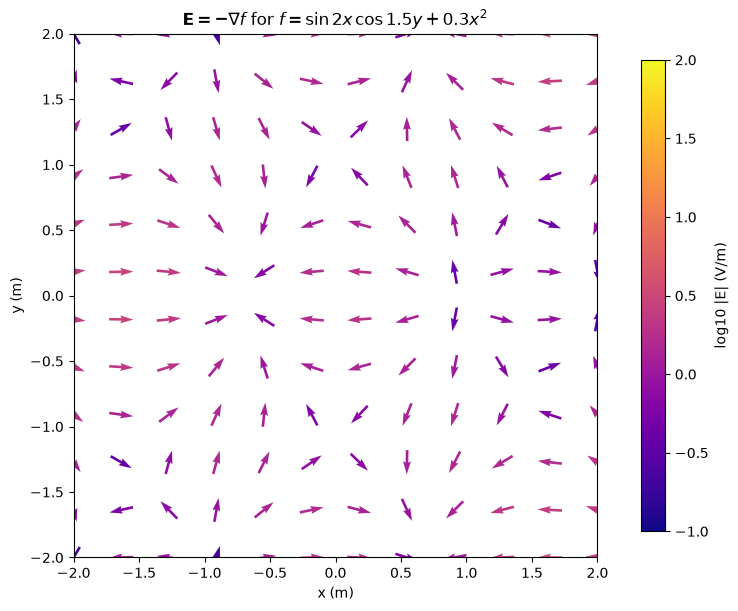

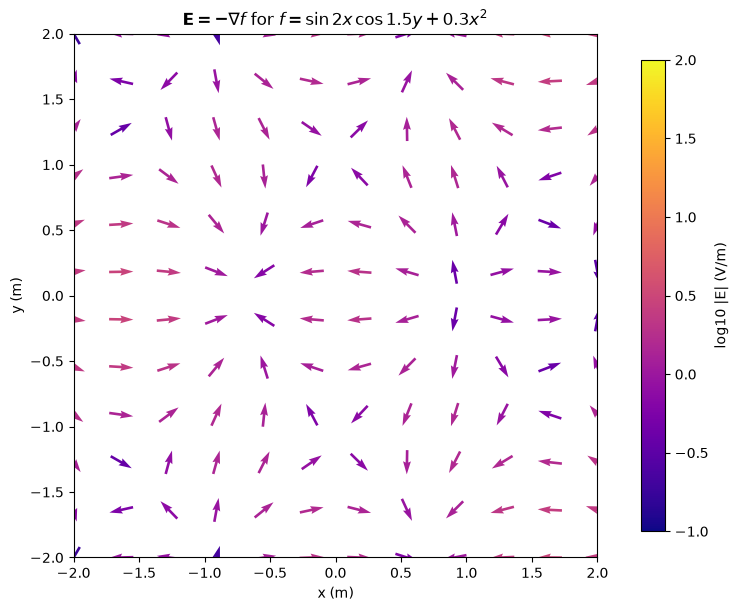

In [6]:
nx = 101
xs = np.linspace(-2.0, 2.0, nx)
dx = xs[1] - xs[0]
X, Y = np.meshgrid(xs, xs)          # grids indexed [y, x]
f = np.sin(2 * X) * np.cos(1.5 * Y) + 0.3 * X**2
zero = np.zeros_like(f)

E, B = eds.fields_from_potentials(f, (zero, zero), dx)
Ex, Ey = E[0], E[1]                  # components in (x, y) order

# discrete curl of E: (curl z) = dEy/dx - dEx/dy
curl_z = np.gradient(Ey, dx, axis=1) - np.gradient(Ex, dx, axis=0)

# check E really is -grad f
dfdx = np.gradient(f, dx, axis=1)
dfdy = np.gradient(f, dx, axis=0)
print(f"max |curl(-grad f)| = {np.abs(curl_z).max():.3e}")
print(f"max |E + grad f|    = {max(np.abs(Ex + dfdx).max(), np.abs(Ey + dfdy).max()):.3e}")
print(f"max |B| (curl of A = 0) = {np.abs(B[0]).max():.3e}")

def e_grad_f(X, Y):
    return -(2 * np.cos(2 * X) * np.cos(1.5 * Y) + 0.6 * X), 1.5 * np.sin(2 * X) * np.sin(1.5 * Y)

fig, ax = eds.plot_vector_field(
    e_grad_f, extent=2.0,
    title=r"$\mathbf{E}=-\nabla f$ for $f=\sin 2x\,\cos 1.5y + 0.3x^2$",
)
fig

## Identity 2: $\nabla \cdot (\nabla \times \mathbf{A}) = 0$

The divergence of any curl vanishes — mixed partial derivatives commute — and this is what makes it legitimate to write $\mathbf{B} = \nabla \times \mathbf{A}$: only a divergence-free field can be a curl. We take a smooth 3D vector potential, form its curl with finite differences, and take the divergence of the result on a $41^3$ grid. The divergence is zero to machine precision, even though the curl itself is very much not.

max |curl A|       = 2.9500
max |div(curl A)|  = 1.110e-14


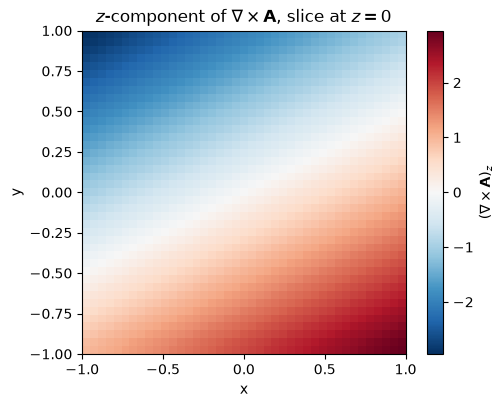

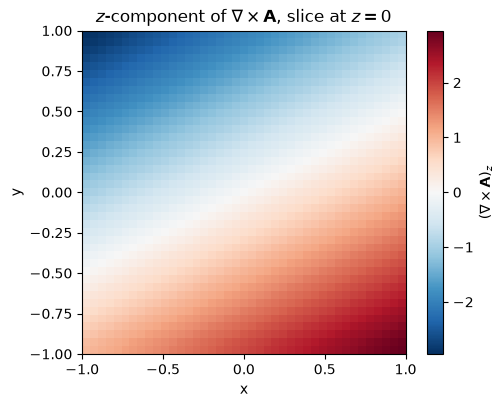

In [7]:
n = 41
xs = np.linspace(-1.0, 1.0, n)
dx = xs[1] - xs[0]
X, Y, Z = np.meshgrid(xs, xs, xs, indexing="ij")

Ax, Ay, Az = Y**2, X * Z, np.sin(X) * Y
grad = lambda F: np.gradient(F, dx, axis=(0, 1, 2))

dAx_dx, dAx_dy, dAx_dz = grad(Ax)
dAy_dx, dAy_dy, dAy_dz = grad(Ay)
dAz_dx, dAz_dy, dAz_dz = grad(Az)

curl = (dAz_dy - dAy_dz, dAx_dz - dAz_dx, dAy_dx - dAx_dy)
div_curl = sum(np.gradient(c, dx, axis=k) for c, k in zip(curl, (0, 1, 2)))

print(f"max |curl A|       = {max(np.abs(c).max() for c in curl):.4f}")
print(f"max |div(curl A)|  = {np.abs(div_curl).max():.3e}")

fig, ax = plt.subplots(figsize=(5.5, 4.2))
im = ax.imshow(curl[2][n // 2], extent=[-1, 1, -1, 1], origin="lower", cmap="RdBu_r")
fig.colorbar(im, ax=ax, label=r"$(\nabla\times\mathbf{A})_z$")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(r"$z$-component of $\nabla\times\mathbf{A}$, slice at $z=0$")
fig

## The inverse problem: recovering the source from the potential

Now run Poisson's equation backwards. We build the potential of a known point charge ($q = 1$ at $\mathbf{r}_0 = (0.11, 0.07, 0.03)$, nudged off the grid points because $V$ diverges there) on a $65^3$ grid, apply $\rho = -\varepsilon_0 \nabla^2 V$ with `eds.laplacian`, and compare with a narrow Gaussian delta of total charge $q$ centered on the source. The recovered density is a discrete delta: a spike spanning a few cells whose **integral** reproduces the true charge, which is all the delta function ever promises.

recovered total charge  sum(rho_rec) * dx^3 = 1.025733  (true q = 1.0)
Gaussian delta total charge              = 1.000000


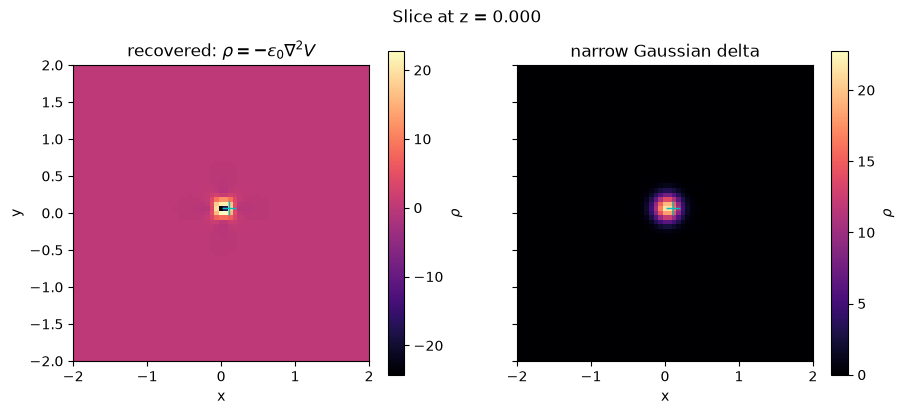

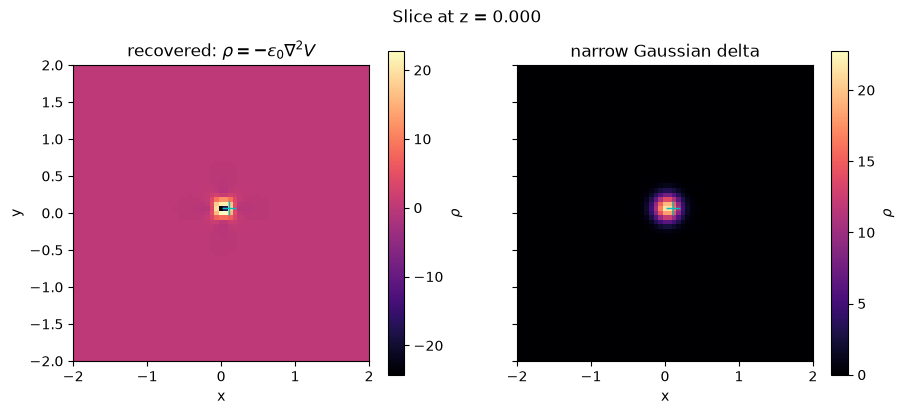

In [8]:
n = 65
xs = np.linspace(-2.0, 2.0, n)
dx = xs[1] - xs[0]
X, Y, Z = np.meshgrid(xs, xs, xs, indexing="ij")
pts = np.stack([X.ravel(), Y.ravel(), Z.ravel()], axis=1)

q_true = 1.0
r0 = np.array([0.11, 0.07, 0.03])
V = eds.point_charge_potential(q_true, r0, pts).reshape(n, n, n)

rho_rec = -eds.EPSILON_0 * eds.laplacian(V, dx)
print(f"recovered total charge  sum(rho_rec) * dx^3 = {rho_rec.sum() * dx**3 :.6f}  (true q = {q_true})")

sigma = 2 * dx
g = (eds.gaussian_delta(xs, r0[0], sigma)[:, None, None]
     * eds.gaussian_delta(xs, r0[1], sigma)[None, :, None]
     * eds.gaussian_delta(xs, r0[2], sigma)[None, None, :])
print(f"Gaussian delta total charge              = {g.sum() * dx**3 :.6f}")

k = np.argmin(np.abs(xs - r0[2]))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), sharey=True)
vmax = max(rho_rec[k].max(), g[k].max())
for ax_, data, title in [
    (axes[0], rho_rec[k], r"recovered: $\rho=-\varepsilon_0\nabla^2 V$"),
    (axes[1], g[k], "narrow Gaussian delta"),
]:
    im = ax_.imshow(data, extent=[-2, 2, -2, 2], origin="lower", cmap="magma", vmax=vmax)
    fig.colorbar(im, ax=ax_, label=r"$\rho$")
    ax_.plot(r0[0], r0[1], "c+", markersize=10)
    ax_.set_xlabel("x")
    ax_.set_title(title)
axes[0].set_ylabel("y")
fig.suptitle(f"Slice at z = {xs[k]:.3f}")
fig

## Exercises

1. **Conceptual.** Using Gauss's law and the flux integral $\oint \hat{\mathbf{r}}/r^2 \cdot d\mathbf{a} = 4\pi$, explain why $\nabla^2(1/r)$ must be proportional to $\delta^3(\mathbf{r})$ and fix the constant of proportionality. Why is $1/r$ harmonic everywhere else?

2. **Coding.** With `eds.gaussian_delta` on `x = np.linspace(-1, 1, 201)`, find the smallest $\sigma$ (to two significant figures) for which `np.trapz(g, x)` deviates from 1 by more than $10^{-6}$. Explain the role of the grid spacing in setting that limit.

3. **Coding.** Invent your own smooth $f(x, y)$ (make it non-polynomial), compute $\mathbf{E}$ with `eds.fields_from_potentials(f, (zero, zero), dx)` and verify that $\max|\nabla\times\mathbf{E}| < 10^{-12}$. Explain why this identity is what licenses writing $\mathbf{E} = -\nabla V$.

4. **Coding.** Choose a different vector potential $\mathbf{A}(x, y, z)$ and verify $\nabla\cdot(\nabla\times\mathbf{A}) = 0$ on a $41^3$ grid, as above. Then repeat on a coarse $11^3$ grid: does the identity survive, and what does that tell you about centered-difference stencils and commuting mixed partials?

5. **Conceptual.** The recovered density in the inverse-problem cell is a blob spanning a few cells, not a mathematical delta. Explain this in terms of discretization, and predict what happens to the blob's height and to its integral as $\Delta x \to 0$.

6. **Coding.** Repeat the inverse problem with $q = -3.0$ and the source at $(-0.5, -0.25, 0.1)$, using a $65^3$ grid. Check that the recovered total charge matches in both magnitude and sign. Then deliberately place the charge exactly on a grid point and observe that `eds.point_charge_potential` raises an error — explain why the potential diverges there and why the package refuses to soften it.